# ANLY 735 | Replication Laboratory #3
## When the Test Environment Changes
### CivilComments-WILDS: In-Distribution vs Shifted Evaluation

**Researcher:** Arvind Natarajan  
**Replication type:** Partial replication of the WILDS distribution-shift evaluation logic

### Laboratory question
What happens to our conclusion about a fixed toxicity classifier when the predictive task and modeling pipeline remain the same but the evaluation environment changes?

### Research claim
A model that performs well on an in-distribution holdout from the CivilComments-WILDS development environment may show materially different overall, calibration, and subgroup performance when the same fitted pipeline is evaluated on the official shifted test environment.

This notebook intentionally does **not** search for a better model after inspecting shifted performance. The changing evaluation environment is the treatment.

## 1. Reproducibility controls

The analysis fixes the random seed at 735, freezes the text representation and classifier before any shifted-test result is inspected, and uses the same fitted pipeline for both evaluation conditions. The official WILDS test split is used only for final shifted evaluation.

The notebook uses a public processed mirror of CivilComments-WILDS to make the analysis easy to run in Colab. The underlying split and identity metadata originate from the WILDS CivilComments curation.

In [1]:
import os, sys, platform, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    accuracy_score, balanced_accuracy_score, precision_score,
    recall_score, f1_score, confusion_matrix
)
import sklearn, datasets, pyarrow

warnings.filterwarnings("ignore", category=UserWarning)
SEED = 735
np.random.seed(SEED)
ARTIFACT_DIR = Path("lab03_artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)
IDENTITIES = ["male", "female", "LGBTQ", "christian", "muslim", "other_religions", "black", "white"]
print("Seed:", SEED)

Seed: 735


## 2. Load and inspect CivilComments-WILDS

CivilComments-WILDS is a toxicity-classification task. The input is comment text, the binary outcome indicates toxicity, and demographic-identity annotations define meaningful subpopulations. Koh et al. (2021) use this dataset to study subpopulation shift, where the same groups can appear in development and testing but their relative representation and associated difficulty differ.

In [2]:
# Primary public mirror of the processed WILDS CivilComments data.
# If the Hub loader changes, the direct Parquet fallback below preserves reproducibility.
try:
    ds = load_dataset("pietrolesci/civilcomments-wilds", "default")
    train_full = ds["train"].to_pandas()
    wilds_val = ds["validation"].to_pandas()
    ood_test = ds["test"].to_pandas()
    DATA_SOURCE = "Hugging Face mirror: pietrolesci/civilcomments-wilds"
except Exception as e:
    print("Hub loader failed; using direct parquet fallback:", repr(e))
    base = "https://huggingface.co/datasets/pietrolesci/civilcomments-wilds/resolve/main/data"
    train_full = pd.read_parquet(f"{base}/train-00000-of-00001.parquet")
    wilds_val = pd.read_parquet(f"{base}/validation-00000-of-00001.parquet")
    ood_test = pd.read_parquet(f"{base}/test-00000-of-00001.parquet")
    DATA_SOURCE = "Direct Parquet mirror: pietrolesci/civilcomments-wilds"

for name, df in {"train":train_full, "validation":wilds_val, "test":ood_test}.items():
    print(name, df.shape, "toxicity prevalence =", round(df["toxicity"].mean(), 4))
print("Columns:", train_full.columns.tolist())

README.md:   0%|          | 0.00/4.64k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 68.8MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 34.1MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/267516 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/132730 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/45047 [00:00<?, ? examples/s]

train (267516, 21) toxicity prevalence = 0.1134
validation (45047, 21) toxicity prevalence = 0.1117
test (132730, 21) toxicity prevalence = 0.1137
Columns: ['uid', 'id', 'comment_text', 'toxicity', 'has_active_attrs', 'active_attrs', 'male', 'female', 'LGBTQ', 'christian', 'muslim', 'other_religions', 'black', 'white', 'identity_any', 'severe_toxicity', 'obscene', 'threat', 'insult', 'identity_attack', 'sexual_explicit']


In [3]:
# Basic integrity checks
required_cols = {"comment_text", "toxicity", *IDENTITIES}
for name, df in {"train":train_full, "validation":wilds_val, "test":ood_test}.items():
    missing_cols = required_cols.difference(df.columns)
    assert not missing_cols, f"{name} missing columns: {missing_cols}"
    assert df["comment_text"].notna().all(), f"Missing text in {name}"
    assert set(df["toxicity"].unique()).issubset({0,1}), f"Non-binary labels in {name}"
print("Integrity checks passed.")

Integrity checks passed.


## 3. Define the two evaluation environments

**Development environment.** The official WILDS training split is the source environment. A stratified 20% holdout is carved out *before fitting* to create an in-distribution (ID) evaluation set that preserves the source mixture.

**Shifted environment.** The official WILDS test split is kept untouched until the final evaluation. It represents the benchmark's naturally occurring subpopulation shift.

The official validation split is loaded for provenance but is not used for tuning. This prevents the shifted evaluation from becoming part of the model-selection loop.

In [4]:
train_dev, id_test = train_test_split(
    train_full,
    test_size=0.20,
    stratify=train_full["toxicity"],
    random_state=SEED,
)
train_dev = train_dev.reset_index(drop=True)
id_test = id_test.reset_index(drop=True)
ood_test = ood_test.reset_index(drop=True)

split_summary = pd.DataFrame({
    "Environment": ["Development", "ID holdout", "Shifted / OOD test"],
    "n": [len(train_dev), len(id_test), len(ood_test)],
    "Toxicity prevalence": [train_dev.toxicity.mean(), id_test.toxicity.mean(), ood_test.toxicity.mean()],
    "Any identity mention": [train_dev.has_active_attrs.mean() if "has_active_attrs" in train_dev else train_dev[IDENTITIES].any(axis=1).mean(),
                             id_test.has_active_attrs.mean() if "has_active_attrs" in id_test else id_test[IDENTITIES].any(axis=1).mean(),
                             ood_test.has_active_attrs.mean() if "has_active_attrs" in ood_test else ood_test[IDENTITIES].any(axis=1).mean()]
})
split_summary

,Environment,n,Toxicity prevalence,Any identity mention
0,Development,214012,0.113424,0.401996
1,ID holdout,53504,0.113431,0.402194
2,Shifted / OOD test,132730,0.113727,0.392986


## 4. Hold the modeling strategy steady

The fixed baseline is deliberately modest: TF-IDF text features plus L2-regularized logistic regression. This is not intended to reproduce the paper's transformer architecture. It is a partial replication designed to isolate the environmental comparison. No hyperparameter search is performed after seeing the shifted test results.

In [5]:
vectorizer = TfidfVectorizer(
    lowercase=True,
    strip_accents="unicode",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.98,
    max_features=30_000,
    sublinear_tf=True,
    dtype=np.float32,
)

X_train = vectorizer.fit_transform(train_dev["comment_text"])
X_id = vectorizer.transform(id_test["comment_text"])
X_ood = vectorizer.transform(ood_test["comment_text"])

y_train = train_dev["toxicity"].to_numpy()
y_id = id_test["toxicity"].to_numpy()
y_ood = ood_test["toxicity"].to_numpy()

model = LogisticRegression(
    penalty="l2",
    C=1.0,
    solver="liblinear",
    max_iter=1000,
    random_state=SEED,
)
model.fit(X_train, y_train)
print("Model fitted. Vocabulary size:", len(vectorizer.vocabulary_))

Model fitted. Vocabulary size: 30000


## 5. Evaluate ID and shifted performance

The same fitted vectorizer and classifier are evaluated without refitting. ROC-AUC is the primary discrimination metric. PR-AUC is included because toxicity is relatively uncommon. Brier score and expected calibration error (ECE) provide probability-quality evidence. Accuracy and balanced accuracy make the performance change easy to interpret.

In [6]:
def expected_calibration_error(y_true, prob, n_bins=10):
    y_true = np.asarray(y_true)
    prob = np.asarray(prob)
    bins = np.linspace(0, 1, n_bins + 1)
    ids = np.digitize(prob, bins[1:-1], right=True)
    ece = 0.0
    for b in range(n_bins):
        mask = ids == b
        if mask.any():
            ece += mask.mean() * abs(y_true[mask].mean() - prob[mask].mean())
    return float(ece)

def evaluate(y_true, prob, threshold=0.5):
    pred = (prob >= threshold).astype(int)
    return {
        "ROC-AUC": roc_auc_score(y_true, prob),
        "PR-AUC": average_precision_score(y_true, prob),
        "Brier": brier_score_loss(y_true, prob),
        "ECE": expected_calibration_error(y_true, prob),
        "Accuracy": accuracy_score(y_true, pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, pred),
        "Precision": precision_score(y_true, pred, zero_division=0),
        "Recall": recall_score(y_true, pred, zero_division=0),
        "F1": f1_score(y_true, pred, zero_division=0),
    }

p_id = model.predict_proba(X_id)[:,1]
p_ood = model.predict_proba(X_ood)[:,1]

id_metrics = evaluate(y_id, p_id)
ood_metrics = evaluate(y_ood, p_ood)

rows = []
for metric in id_metrics:
    rows.append({
        "Metric": metric,
        "In-Distribution": id_metrics[metric],
        "Shifted Environment": ood_metrics[metric],
        "Change (OOD - ID)": ood_metrics[metric] - id_metrics[metric],
    })
metrics_table = pd.DataFrame(rows)
metrics_table.to_csv(ARTIFACT_DIR/"lab03_id_ood_metrics.csv", index=False)
metrics_table.round(4)

,Metric,In-Distribution,Shifted Environment,Change (OOD - ID)
0,ROC-AUC,0.9027,0.9030,0.0003
1,PR-AUC,0.6289,0.6302,0.0013
2,Brier,0.0650,0.0650,0.0000
3,ECE,0.0255,0.0265,0.0010
4,Accuracy,0.9124,0.9127,0.0003
5,Balanced Accuracy,0.6515,0.6549,0.0034
6,Precision,0.7844,0.7826,-0.0018
7,Recall,0.3141,0.3212,0.0072
8,F1,0.4485,0.4555,0.0070


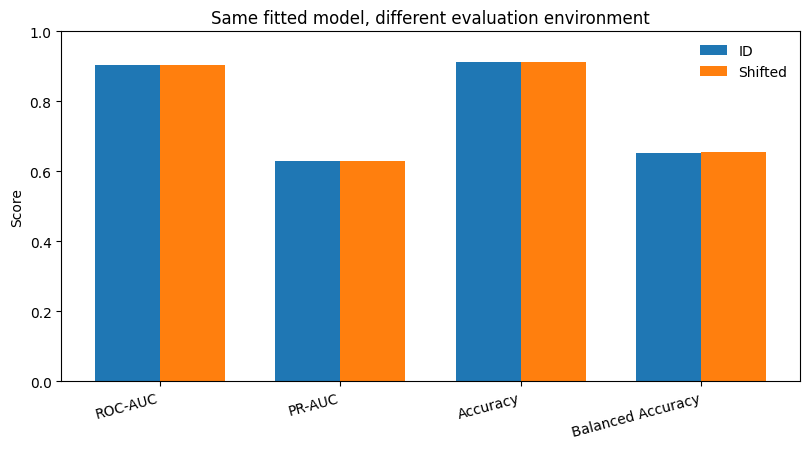

In [7]:
# One concise visualization of higher-is-better headline metrics.
plot_metrics = ["ROC-AUC", "PR-AUC", "Accuracy", "Balanced Accuracy"]
plot_df = metrics_table[metrics_table.Metric.isin(plot_metrics)].copy()

x = np.arange(len(plot_metrics))
width = 0.36
fig, ax = plt.subplots(figsize=(8.2, 4.6))
ax.bar(x - width/2, [id_metrics[m] for m in plot_metrics], width, label="ID")
ax.bar(x + width/2, [ood_metrics[m] for m in plot_metrics], width, label="Shifted")
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_xticks(x, plot_metrics, rotation=15, ha="right")
ax.set_title("Same fitted model, different evaluation environment")
ax.legend(frameon=False)
fig.tight_layout()
FIG_PATH = ARTIFACT_DIR/"lab03_id_vs_shifted.png"
fig.savefig(FIG_PATH, dpi=180, bbox_inches="tight")
plt.show()

## 6. Look beneath the average: subgroup robustness

CivilComments-WILDS is particularly useful because the benchmark was designed around demographic subpopulations. The analysis therefore reports identity-specific performance and the WILDS-style worst-group accuracy over identity-by-label groups. A strong average score does not establish that every subgroup is robust.

In [8]:
def safe_auc(y, p):
    return roc_auc_score(y, p) if len(np.unique(y)) == 2 else np.nan

def subgroup_metrics(df, y, p, env_name):
    pred = (p >= 0.5).astype(int)
    out = []
    for g in IDENTITIES:
        mask = df[g].to_numpy() == 1
        if mask.sum() == 0:
            continue
        yy, pp, pr = y[mask], p[mask], pred[mask]
        tn, fp, fn, tp = confusion_matrix(yy, pr, labels=[0,1]).ravel()
        out.append({
            "Environment": env_name,
            "Identity": g,
            "n": int(mask.sum()),
            "Prevalence": yy.mean(),
            "ROC-AUC": safe_auc(yy, pp),
            "PR-AUC": average_precision_score(yy, pp) if yy.sum() > 0 else np.nan,
            "Accuracy": accuracy_score(yy, pr),
            "Recall / TPR": tp/(tp+fn) if (tp+fn) else np.nan,
            "Specificity / TNR": tn/(tn+fp) if (tn+fp) else np.nan,
            "Brier": brier_score_loss(yy, pp),
        })
    return pd.DataFrame(out)

sub_id = subgroup_metrics(id_test, y_id, p_id, "ID")
sub_ood = subgroup_metrics(ood_test, y_ood, p_ood, "Shifted")
subgroups = pd.concat([sub_id, sub_ood], ignore_index=True)
subgroups.to_csv(ARTIFACT_DIR/"lab03_subgroup_metrics.csv", index=False)
subgroups.round(4)

,Environment,Identity,n,Prevalence,ROC-AUC,PR-AUC,Accuracy,Recall / TPR,Specificity / TNR,Brier
0,ID,male,5882,0.1464,0.8745,0.6117,0.8863,0.3345,0.9809,0.0849
1,ID,female,7201,0.1401,0.8821,0.6279,0.8920,0.3092,0.9869,0.0803
2,ID,LGBTQ,1724,0.2755,0.8069,0.6208,0.7691,0.3032,0.9464,0.1553
3,ID,christian,5373,0.0878,0.8975,0.5177,0.9211,0.2203,0.9886,0.0576
4,ID,muslim,2767,0.2219,0.8095,0.5937,0.8171,0.3046,0.9633,0.1308
5,ID,other_religions,1317,0.1465,0.8649,0.5868,0.8815,0.3161,0.9786,0.0882
6,ID,black,1979,0.3249,0.7984,0.6932,0.7736,0.4526,0.9281,0.1622
7,ID,white,3374,0.2709,0.8019,0.6322,0.7854,0.3993,0.9289,0.1487
8,Shifted,male,14206,0.1539,0.8738,0.6193,0.8789,0.3379,0.9774,0.0885
9,Shifted,female,16335,0.1379,0.8757,0.6098,0.8901,0.3020,0.9842,0.0809


In [9]:
def wilds_worst_group_accuracy(df, y, p):
    pred = (p >= 0.5).astype(int)
    group_rows = []
    for g in IDENTITIES:
        ident = df[g].to_numpy() == 1
        for label in (0,1):
            mask = ident & (y == label)
            if mask.sum() == 0:
                continue
            acc = accuracy_score(y[mask], pred[mask])
            group_rows.append({"Identity":g, "Label":label, "n":int(mask.sum()), "Accuracy":acc})
    gdf = pd.DataFrame(group_rows)
    worst = gdf.loc[gdf.Accuracy.idxmin()].to_dict()
    return gdf, worst

id_groups, id_worst = wilds_worst_group_accuracy(id_test, y_id, p_id)
ood_groups, ood_worst = wilds_worst_group_accuracy(ood_test, y_ood, p_ood)
id_groups.assign(Environment="ID").to_csv(ARTIFACT_DIR/"lab03_id_identity_label_groups.csv", index=False)
ood_groups.assign(Environment="Shifted").to_csv(ARTIFACT_DIR/"lab03_ood_identity_label_groups.csv", index=False)
print("ID worst group:", id_worst)
print("OOD worst group:", ood_worst)

ID worst group: {'Identity': 'christian', 'Label': 1, 'n': 472, 'Accuracy': 0.22033898305084745}
OOD worst group: {'Identity': 'christian', 'Label': 1, 'n': 1254, 'Accuracy': 0.2551834130781499}


## 7. Diagnose before fixing

The purpose of this section is not to prove a single causal explanation. It asks whether the shifted environment differs in ways that make degradation plausible. We inspect outcome prevalence, identity composition, text length, and the largest changes in average TF-IDF feature weight. These are diagnostic signals, not proof that any one feature caused the performance change.

In [10]:
def environment_diagnostics(df, name):
    lengths = df.comment_text.str.split().str.len()
    return {
        "Environment": name,
        "n": len(df),
        "Toxicity prevalence": df.toxicity.mean(),
        "Any identity mention": df[IDENTITIES].any(axis=1).mean(),
        "Median words": lengths.median(),
        "Mean words": lengths.mean(),
        "90th pct words": lengths.quantile(.90),
    }

diag = pd.DataFrame([
    environment_diagnostics(train_dev, "Development"),
    environment_diagnostics(id_test, "ID"),
    environment_diagnostics(ood_test, "Shifted"),
])
diag.to_csv(ARTIFACT_DIR/"lab03_environment_diagnostics.csv", index=False)
diag.round(4)

,Environment,n,Toxicity prevalence,Any identity mention,Median words,Mean words,90th pct words
0,Development,214012,0.1134,0.4020,45.0,60.7766,148.0
1,ID,53504,0.1134,0.4022,45.0,61.0234,148.0
2,Shifted,132730,0.1137,0.3930,44.0,60.3226,146.0


In [11]:
identity_shift = []
for g in IDENTITIES:
    identity_shift.append({
        "Identity": g,
        "ID proportion": id_test[g].mean(),
        "Shifted proportion": ood_test[g].mean(),
        "Change": ood_test[g].mean() - id_test[g].mean(),
    })
identity_shift = pd.DataFrame(identity_shift).sort_values("Change", key=np.abs, ascending=False)
identity_shift.to_csv(ARTIFACT_DIR/"lab03_identity_composition_shift.csv", index=False)
identity_shift.round(4)

,Identity,ID proportion,Shifted proportion,Change
1,female,0.1346,0.1231,-0.0115
7,white,0.0631,0.0592,-0.0039
0,male,0.1099,0.1070,-0.0029
5,other_religions,0.0246,0.0261,0.0015
2,LGBTQ,0.0322,0.0331,0.0009
6,black,0.0370,0.0364,-0.0006
4,muslim,0.0517,0.0520,0.0003
3,christian,0.1004,0.1002,-0.0002


In [12]:
# Predictor-shift diagnostic: terms with the largest absolute difference
# in mean TF-IDF weight across ID and shifted environments.
id_mean = np.asarray(X_id.mean(axis=0)).ravel()
ood_mean = np.asarray(X_ood.mean(axis=0)).ravel()
terms = np.asarray(vectorizer.get_feature_names_out())
delta = ood_mean - id_mean
idx = np.argsort(np.abs(delta))[::-1][:20]
term_shift = pd.DataFrame({
    "Term": terms[idx],
    "ID mean TF-IDF": id_mean[idx],
    "Shifted mean TF-IDF": ood_mean[idx],
    "Difference": delta[idx],
})
term_shift.to_csv(ARTIFACT_DIR/"lab03_top_shifted_terms.csv", index=False)
term_shift.round(6)

,Term,ID mean TF-IDF,Shifted mean TF-IDF,Difference
0,women,0.007003,0.006123,-0.000881
1,she,0.006497,0.006029,-0.000468
2,white,0.006251,0.005798,-0.000453
3,but,0.011701,0.011264,-0.000438
4,then,0.005527,0.005158,-0.000369
5,their,0.009939,0.010302,0.000363
6,as,0.013938,0.013583,-0.000356
7,people,0.009935,0.009587,-0.000349
8,this,0.015006,0.014659,-0.000347
9,money,0.003483,0.003820,0.000338


## 8. Evidence-based judgment

The deployment judgment is intentionally conservative. The rule below is fixed before inspecting the final printed verdict:

- **REVALIDATE** if the shifted ROC-AUC declines by at least 0.03, Brier score worsens by at least 0.02, or shifted worst-group accuracy is below 0.70.
- **DEPLOY WITH SAFEGUARDS** if those conditions are not met but any headline metric worsens or subgroup variation remains material.
- **DEPLOY** only if overall and subgroup evidence is stable under the shifted evaluation.

These are laboratory decision thresholds, not universal operational standards.

In [13]:
auc_drop = id_metrics["ROC-AUC"] - ood_metrics["ROC-AUC"]
brier_worsen = ood_metrics["Brier"] - id_metrics["Brier"]
worst_ood_acc = float(ood_worst["Accuracy"])

if (auc_drop >= 0.03) or (brier_worsen >= 0.02) or (worst_ood_acc < 0.70):
    verdict = "REVALIDATE"
elif any(ood_metrics[m] < id_metrics[m] for m in ["ROC-AUC","PR-AUC","Accuracy","Balanced Accuracy"]):
    verdict = "DEPLOY WITH SAFEGUARDS"
else:
    verdict = "DEPLOY"

print("Deployment judgment:", verdict)
print(f"ROC-AUC drop: {auc_drop:.4f}")
print(f"Brier worsening: {brier_worsen:.4f}")
print(f"Shifted worst-group accuracy: {worst_ood_acc:.4f}")

Deployment judgment: REVALIDATE
ROC-AUC drop: -0.0003
Brier worsening: 0.0000
Shifted worst-group accuracy: 0.2552


## 9. Comparison with Koh et al. (2021)

Koh et al. report a pronounced CivilComments gap under their original ERM benchmark: Table 1 lists 92.2% under the benchmark's average-performance comparison and 56.0% worst-group accuracy under subpopulation-shift evaluation. The present laboratory does not attempt a numerical reproduction of those transformer results. It reproduces the methodological claim with the same benchmark family and shift logic using a transparent linear text classifier.

The relevant question is therefore whether the direction of evidence is reproduced: does apparently strong source-like evaluation become materially less reassuring when the environment and subgroup composition change?

## 10. Session information


In [14]:
session_info = {
    "python": sys.version,
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scikit_learn": sklearn.__version__,
    "datasets": datasets.__version__,
    "pyarrow": pyarrow.__version__,
    "seed": SEED,
    "data_source": DATA_SOURCE,
}
print(json.dumps(session_info, indent=2))
with open(ARTIFACT_DIR/"session_info.json", "w") as f:
    json.dump(session_info, f, indent=2)

{
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "scikit_learn": "1.6.1",
  "datasets": "4.8.5",
  "pyarrow": "23.0.1",
  "seed": 735,
  "data_source": "Hugging Face mirror: pietrolesci/civilcomments-wilds"
}
